In [1]:
import pandas as pd
import json
import numpy as np
import matplotlib.pyplot as plt

# **Part 1:** Data preparation

In [2]:
data_path = "../../data/fashion_products_dataset.json"

# Load the JSON data from the file
with open(data_path) as fp:
    data = json.load(fp)

# Print the datatype of the loaded data
print("Datatype of the loaded data:", type(data))

# Print the number of products in the dataset and the first product if the data is a list
if isinstance(data, list):
    print("Number of products in the dataset:", len(data))
    print("First product in the dataset:", data[0])

Datatype of the loaded data: <class 'list'>
Number of products in the dataset: 28080
First product in the dataset: {'_id': 'fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a', 'actual_price': '2,999', 'average_rating': '3.9', 'brand': 'York', 'category': 'Clothing and Accessories', 'crawled_at': 1612987911000, 'description': 'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India', 'discount': '69% off', 'images': ['https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-1005combo2-yorker-original-imafczg3xfh5qqd4.jpeg?q=70', 'https://rukminim1.flixcart.com/image/128/128/jr58l8w0/track-pant/w/d/a/l-1005combo8-yorker-original-imafczg3pgtxgraq.jpeg?q=70'], 'out_of_stock': False, 'pid': 'TKPFCZ9EA7H5FYZH', 'product_details': [{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid

In [3]:
# Create a DataFrame from the loaded data
df = pd.DataFrame(data)

# Display the shape of the DataFrame, the first few rows, and the column names
print("Dataset shape:", df.shape)
display(df.head())
print("Column names:", df.columns.tolist())


Dataset shape: (28080, 17)


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,1612987911000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,1612987912000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,1612987913000,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,1612987913000,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...


Column names: ['_id', 'actual_price', 'average_rating', 'brand', 'category', 'crawled_at', 'description', 'discount', 'images', 'out_of_stock', 'pid', 'product_details', 'seller', 'selling_price', 'sub_category', 'title', 'url']


### Exploring Data

In [4]:
# Display information about the DataFrame
df.info()

# Check for missing values in the DataFrame
display(df.isnull().sum())

# Check for duplicate product IDs in the DataFrame
print("Duplicate pids:", df["pid"].duplicated().sum())

expected_fields = ["pid", "title", "description", "brand", "category",
                   "sub_category", "product_details", "seller", "out_of_stock",
                   "selling_price", "discount", "actual_price", "average_rating", "url"]

# Check for missing columns in the DataFrame
print("Missing columns:", set(expected_fields) - set(df.columns))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   _id              28080 non-null  object
 1   actual_price     28080 non-null  object
 2   average_rating   28080 non-null  object
 3   brand            28080 non-null  object
 4   category         28080 non-null  object
 5   crawled_at       28080 non-null  int64 
 6   description      28080 non-null  object
 7   discount         28080 non-null  object
 8   images           28080 non-null  object
 9   out_of_stock     28080 non-null  bool  
 10  pid              28080 non-null  object
 11  product_details  28080 non-null  object
 12  seller           28080 non-null  object
 13  selling_price    28080 non-null  object
 14  sub_category     28080 non-null  object
 15  title            28080 non-null  object
 16  url              28080 non-null  object
dtypes: bool(1), int64(1), object(15

_id                0
actual_price       0
average_rating     0
brand              0
category           0
crawled_at         0
description        0
discount           0
images             0
out_of_stock       0
pid                0
product_details    0
seller             0
selling_price      0
sub_category       0
title              0
url                0
dtype: int64

Duplicate pids: 0
Missing columns: set()


In [5]:
print(df["product_details"].iloc[0])

display(
    df[["pid", "title", "description", "brand", "category"]].head(10)
)

[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]


,pid,title,description,brand,category
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants",Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
5,TKPFCZ9EFK9DNWDA,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
6,TKPFDABN3GXYPFHE,Solid Women Dark Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
7,TKPFCZ9ESGZYT8NH,Solid Women Beige Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
8,TKPFCZ9DYU33FFXS,Solid Women Black Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories
9,TKPFDABN4NQFVKZY,Solid Men Grey Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories


In [6]:
text_columns = [
    "title", "description", "brand", "category",
    "sub_category", "seller"
]

# Check for empty strings and whitespace-only values
for col in text_columns:
    empty = df[col].astype(str).str.strip().eq("").sum()
    print(f"{col}: {empty} empty values")

# Check whether product IDs are unique
print("Unique PIDs:", df["pid"].nunique())
print("Total rows:", len(df))

# Inspect distinct Boolean values
print(df["out_of_stock"].value_counts(dropna=False))

title: 0 empty values
description: 11150 empty values
brand: 2009 empty values
category: 0 empty values
sub_category: 0 empty values
seller: 1643 empty values
Unique PIDs: 28080
Total rows: 28080
out_of_stock
False    26436
True      1644
Name: count, dtype: int64


### Pre-processing Data

In [7]:
# Work on a copy to preserve the original DataFrame
df = df.copy()

# Convert prices to numeric values
for col in ["selling_price", "actual_price"]:
    df[col + "_num"] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")

# Extract the discount percentage
df["discount_num"] = pd.to_numeric(df["discount"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")

# Convert ratings to numeric values
df["average_rating_num"] = pd.to_numeric(df["average_rating"].astype(str), errors="coerce")

display(
    df[[
        "selling_price", "selling_price_num",
        "actual_price", "actual_price_num",
        "discount", "discount_num",
        "average_rating", "average_rating_num"
    ]].head(10)
)

numeric_columns = [
    "selling_price_num",
    "actual_price_num",
    "discount_num",
    "average_rating_num"
]

display(df[numeric_columns].isnull().sum())

,selling_price,selling_price_num,actual_price,actual_price_num,discount,discount_num,average_rating,average_rating_num
0,921,921.0,"2,999",2999.0,69% off,69.0,3.9,3.9
1,499,499.0,"1,499",1499.0,66% off,66.0,3.9,3.9
2,931,931.0,"2,999",2999.0,68% off,68.0,3.9,3.9
3,911,911.0,"2,999",2999.0,69% off,69.0,3.9,3.9
4,943,943.0,"2,999",2999.0,68% off,68.0,3.9,3.9
5,"1,169",1169.0,"4,499",4499.0,74% off,74.0,3.8,3.8
6,466,466.0,"1,499",1499.0,68% off,68.0,3.8,3.8
7,545,545.0,"1,499",1499.0,63% off,63.0,3.8,3.8
8,489,489.0,"1,499",1499.0,67% off,67.0,3.8,3.8
9,531,531.0,"1,499",1499.0,64% off,64.0,3.7,3.7


selling_price_num        2
actual_price_num       777
discount_num           855
average_rating_num    2261
dtype: int64

In [8]:
def flatten_product_details(details):
    if not isinstance(details, list):
        return ""

    attributes = []

    for item in details:
        if isinstance(item, dict):
            for key, value in item.items():
                attributes.append(f"{key} {value}")

    return " ".join(attributes)


df["product_details_text"] = df["product_details"].apply(flatten_product_details)

print(df["product_details_text"].iloc[0])

Style Code 1005COMBO2 Closure Elastic Pockets Side Pockets Fabric Cotton Blend Pattern Solid Color Multicolor


In [9]:
# Find values that failed numeric conversion
for col in numeric_columns:
    failed = df[col].isna()

    # Recover the corresponding original column
    original_col = col.removesuffix("_num")

    print(f"\n{original_col}: {failed.sum()} failed conversions")

    display(
        df.loc[failed, ["pid", original_col]].head(10)
    )


selling_price: 2 failed conversions


,pid,selling_price
19482,SOCFYNKS7XZ3YUKZ,
27574,TKPFZAGJYK9YGRAA,



actual_price: 777 failed conversions


,pid,actual_price
1705,TSHFZ3JEEZC6KTVB,
1734,SOCFH2UDUMG6GMSR,
1891,TKPFZ3JRBVZD3AKM,
1922,SWSFJY5ZBJAVWWJX,
1949,TKPFZ3JRYR599GGY,
1950,TSHFK3W7AZQYSWGF,
1953,JCKFJY5A7Q7XCMHK,
1958,TSHFZ3JDCZQHVU8G,
1964,SOCFYY5RGZHT3AZF,
2020,TSHFK3W7JGJUXFUT,



discount: 855 failed conversions


,pid,discount
1705,TSHFZ3JEEZC6KTVB,
1734,SOCFH2UDUMG6GMSR,
1891,TKPFZ3JRBVZD3AKM,
1922,SWSFJY5ZBJAVWWJX,
1949,TKPFZ3JRYR599GGY,
1950,TSHFK3W7AZQYSWGF,
1953,JCKFJY5A7Q7XCMHK,
1958,TSHFZ3JDCZQHVU8G,
1964,SOCFYY5RGZHT3AZF,
2020,TSHFK3W7JGJUXFUT,



average_rating: 2261 failed conversions


,pid,average_rating
58,CTPFVPZDEQYYBKCT,
137,CTPFVPGH5AGD8PZX,
170,SWTFYHPKSZDBSBGU,
344,BXRFGYQUTHXJKHHP,
363,VESFZGCFZMFCTDV5,
377,VESFZAM6DPFT2VHZ,
380,VESFZANYWFQFYXZ2,
399,VESFZAKZ2ADEZEHM,
451,VESFZAGW4AG8WJUF,
453,TSHFZYYMGNZDR2ZH,


In [10]:
text_columns = ["title", "description", "brand", "category", "sub_category", "seller"]

# Replace empty strings and whitespace-only values with NaN
for col in text_columns:
    df[col] = df[col].replace(r"^\s*$", np.nan, regex=True)

print(df[text_columns].isna().sum())

title               0
description     11150
brand            2009
category            0
sub_category        0
seller           1643
dtype: int64


Top 10 categories:


category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64

Top 10 subcategories:


sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Name: count, dtype: int64

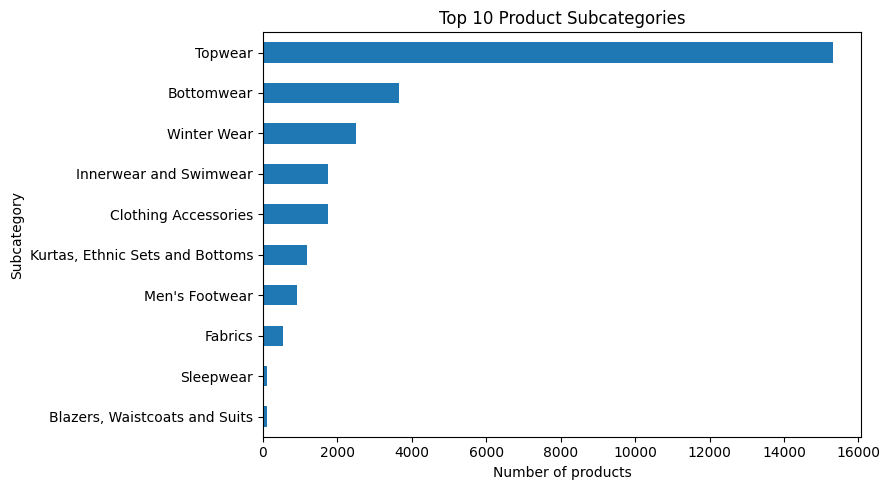

Top 10 brands:


brand
ECKO Unl        951
Free Authori    860
ARBO            806
REEB            802
Pu              798
True Bl         793
Keo             660
Amp             585
Black Beat      548
vims rai        503
Name: count, dtype: int64

In [11]:
# Most common product categories
print("Top 10 categories:")
display(df["category"].value_counts().head(10))

# Most common subcategories
print("Top 10 subcategories:")
display(df["sub_category"].value_counts().head(10))

# Plot the most common subcategories
top_subcategories = df["sub_category"].value_counts().head(10)

top_subcategories.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 Product Subcategories")
plt.xlabel("Number of products")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()

print("Top 10 brands:")
display(df["brand"].value_counts().head(10))

In [12]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import html
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import RegexpTokenizer

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\paola\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [14]:
# English stop words
stop_words = set(stopwords.words("english"))

# Preserve words that may be important for product searches
important_words = {"men", "women", "no", "not", "nor"}
stop_words -= important_words

# Stemmer
stemmer = PorterStemmer()

In [15]:
def preprocess_text(text):
    if not isinstance(text, str) or not text.strip():
        return []

    # 1. HTML unescaping and stripping tags (Bonus cleaning)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)

    # 2. Lowercase
    text = text.lower()

    # 3. Tokenize and remove punctuation
    tokenizer = RegexpTokenizer(r"\b[a-z0-9]+\b")
    tokens = tokenizer.tokenize(text)

    # 4. Remove stop words
    filtered_tokens = [t for t in tokens if t not in stop_words]

    # 5. Apply stemming
    stemmed_tokens = [stemmer.stem(t) for t in filtered_tokens]

    return stemmed_tokens

In [16]:
# Flatten nested product_details list into a single string
df["product_details_text"] = df["product_details"].apply(
    flatten_product_details
)

In [17]:
# Apply preprocessing to the title and description columns

df["title_processed"] = df["title"].apply(preprocess_text)

df["description_processed"] = (df["description"].apply(preprocess_text))

display(df[["title", "title_processed", "description", "description_processed"]].head(10))

,title,title_processed,description,description_processed
0,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
1,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
2,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
3,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
4,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
5,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
6,Solid Women Dark Blue Track Pants,"[solid, women, dark, blue, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
7,Solid Women Beige Track Pants,"[solid, women, beig, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
8,Solid Women Black Track Pants,"[solid, women, black, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
9,Solid Men Grey Track Pants,"[solid, men, grey, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."


In [18]:
# Apply preprocessing to remaining categorical and text fields
other_fields = [
    "brand",
    "category",
    "sub_category",
    "seller",
    "product_details_text",
]

for field in other_fields:
    target_col = (
        "product_details_processed"
        if field == "product_details_text"
        else f"{field}_processed"
    )
    df[target_col] = df[field].apply(preprocess_text)

# Display sample of processed categorical fields
display(
    df[
        [
            "pid",
            "brand_processed",
            "category_processed",
            "sub_category_processed",
            "product_details_processed",
        ]
    ].head(5)
)

,pid,brand_processed,category_processed,sub_category_processed,product_details_processed
0,TKPFCZ9EA7H5FYZH,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo2, closur, elast, pocke..."
1,TKPFCZ9EJZV2UVRZ,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005blue, closur, drawstr, elast..."
2,TKPFCZ9EHFCY5Z4Y,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo4, closur, elast, pocke..."
3,TKPFCZ9ESZZ7YWEF,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo3, closur, elast, pocke..."
4,TKPFCZ9EVXKBSUD7,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo1, closur, drawstr, ela..."


In [19]:
test_queries = [
    "women full sleeve sweatshirt cotton",
    "men slim jeans blue",
]

print("--- Preprocessing Test on Sample Validation Queries ---")
for query in test_queries:
    print(f"Query:     '{query}'")
    print(f"Processed: {preprocess_text(query)}\n")

--- Preprocessing Test on Sample Validation Queries ---
Query:     'women full sleeve sweatshirt cotton'
Processed: ['women', 'full', 'sleev', 'sweatshirt', 'cotton']

Query:     'men slim jeans blue'
Processed: ['men', 'slim', 'jean', 'blue']



In [20]:
# Define the dictionary of separate tokenized fields per PID
separate_fields_corpus = {
    row["pid"]: {
        "title": row["title_processed"],
        "description": row["description_processed"],
        "brand": row["brand_processed"],
        "category": row["category_processed"],
        "sub_category": row["sub_category_processed"],
        "seller": row["seller_processed"],
        "product_details": row["product_details_processed"],
    }
    for _, row in df.iterrows()
}

# Display separate field tokens for a sample PID
sample_pid = df["pid"].iloc[0]
print(
    f"--- Separate Field Token Representation for Sample PID: {sample_pid} ---"
)
for field_name, tokens in separate_fields_corpus[sample_pid].items():
    print(f"{field_name.rjust(18)}: {tokens[:10]}")

--- Separate Field Token Representation for Sample PID: TKPFCZ9EA7H5FYZH ---
             title: ['solid', 'women', 'multicolor', 'track', 'pant']
       description: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look']
             brand: ['york']
          category: ['cloth', 'accessori']
      sub_category: ['bottomwear']
            seller: ['shyam', 'enterpris']
   product_details: ['style', 'code', '1005combo2', 'closur', 'elast', 'pocket', 'side', 'pocket', 'fabric', 'cotton']


In [21]:
# Ensure Boolean type for out_of_stock
df["out_of_stock_bool"] = df["out_of_stock"].astype(bool)

# Build numerical/boolean metadata store keyed by PID
metadata_store = {
    row["pid"]: {
        "out_of_stock": row["out_of_stock_bool"],
        "selling_price": row["selling_price_num"],
        "actual_price": row["actual_price_num"],
        "discount_percent": row["discount_num"],
        "average_rating": row["average_rating_num"],
    }
    for _, row in df.iterrows()
}


def filter_products(
    max_price=None,
    min_rating=None,
    in_stock_only=True,
    min_discount=None,
):
    """Filters product PIDs based on structured numerical/boolean metadata criteria."""
    matching_pids = []
    for pid, meta in metadata_store.items():
        if in_stock_only and meta["out_of_stock"]:
            continue
        if (
            max_price is not None
            and pd.notna(meta["selling_price"])
            and meta["selling_price"] > max_price
        ):
            continue
        if (
            min_rating is not None
            and pd.notna(meta["average_rating"])
            and meta["average_rating"] < min_rating
        ):
            continue
        if (
            min_discount is not None
            and pd.notna(meta["discount_percent"])
            and meta["discount_percent"] < min_discount
        ):
            continue
        matching_pids.append(pid)
    return matching_pids


# Test metadata range filtering query
filtered_pids = filter_products(
    max_price=1000, min_rating=4.0, in_stock_only=True, min_discount=50.0
)
print(f"Total products in dataset: {len(df)}")
print(
    f"Products matching filter (Price <= 1000, Rating >= 4.0, Discount >= 50%, In Stock): {len(filtered_pids)}"
)

# Display sample metadata from the store
sample_pid = df["pid"].iloc[0]
print(f"\n--- Metadata Store Sample for PID: {sample_pid} ---")
print(metadata_store[sample_pid])

Total products in dataset: 28080
Products matching filter (Price <= 1000, Rating >= 4.0, Discount >= 50%, In Stock): 4781

--- Metadata Store Sample for PID: TKPFCZ9EA7H5FYZH ---
{'out_of_stock': False, 'selling_price': 921.0, 'actual_price': 2999.0, 'discount_percent': 69.0, 'average_rating': 3.9}


### Exploratory Data Analysis

In [22]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Total Unique Vocabulary Size: 4896 tokens
Average Title Length: 6.27 tokens
Average Description Length: 18.90 tokens


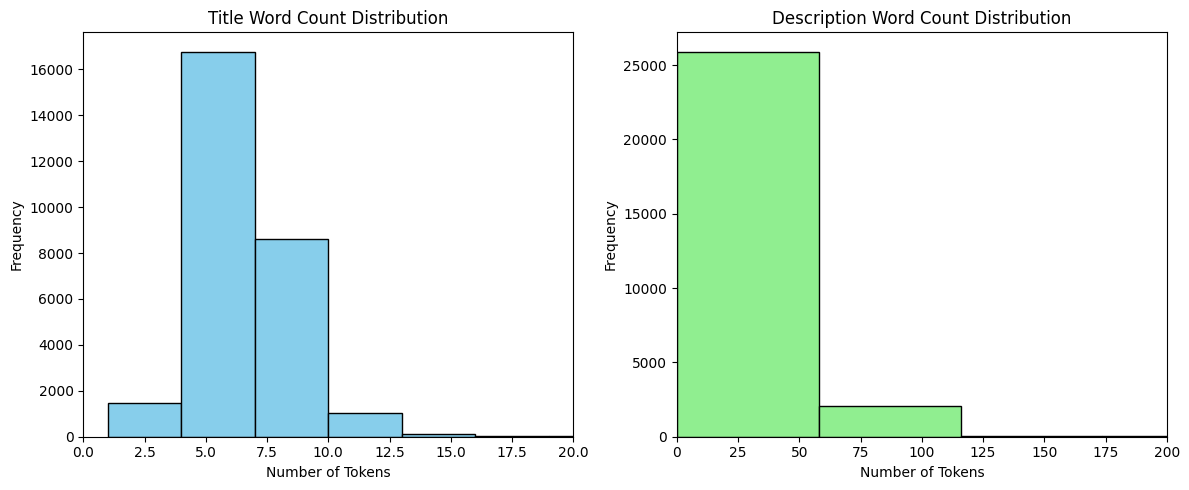

In [23]:
# Calculate word counts for each document
df['title_word_count'] = df['title_processed'].apply(lambda x: len(x) if isinstance(x, list) else 0)
df['desc_word_count'] = df['description_processed'].apply(lambda x: len(x) if isinstance(x, list) else 0)

# Extract vocabulary size
all_title_tokens = [token for tokens in df['title_processed'].dropna() for token in tokens]
all_desc_tokens = [token for tokens in df['description_processed'].dropna() for token in tokens]
total_vocabulary = set(all_title_tokens + all_desc_tokens)

print(f"Total Unique Vocabulary Size: {len(total_vocabulary)} tokens")
print(f"Average Title Length: {df['title_word_count'].mean():.2f} tokens")
print(f"Average Description Length: {df['desc_word_count'].mean():.2f} tokens")

# Plot Word Count Distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df['title_word_count'].plot(kind='hist', bins=10, ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Title Word Count Distribution')
axes[0].set_xlabel('Number of Tokens')
axes[0].set_xlim(0, 20)

df['desc_word_count'].plot(kind='hist', bins=10, ax=axes[1], color='lightgreen', edgecolor='black')
axes[1].set_title('Description Word Count Distribution')
axes[1].set_xlabel('Number of Tokens')
axes[1].set_xlim(0, 200)

plt.tight_layout()
plt.show()

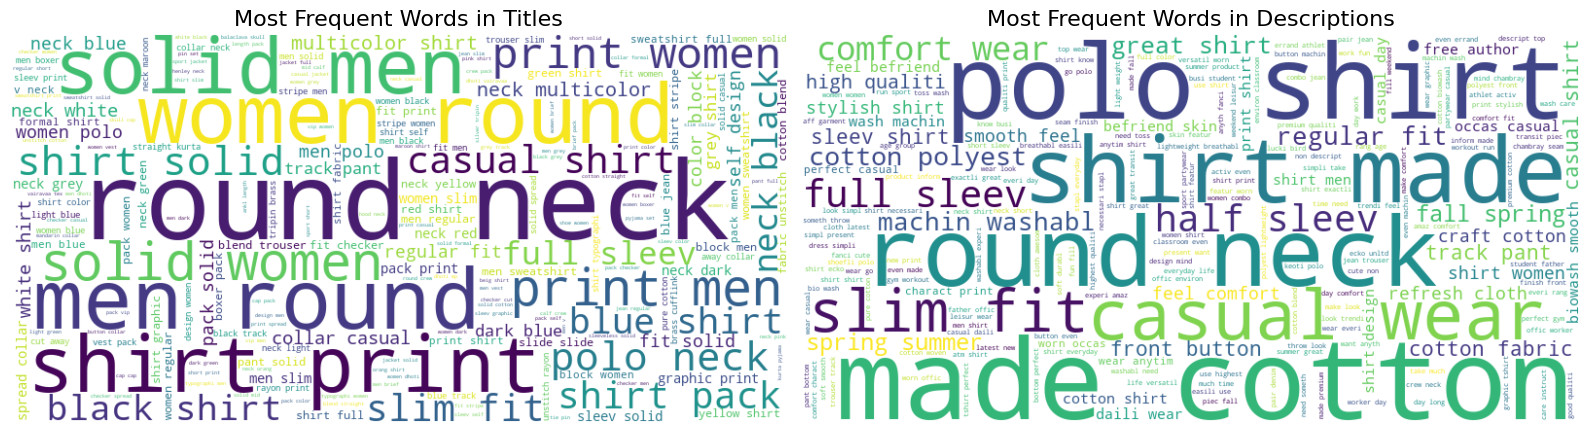

In [24]:
from wordcloud import WordCloud

# Join all processed tokens back into a single string for the word cloud
title_text = " ".join(all_title_tokens)
desc_text = " ".join(all_desc_tokens)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Title Word Cloud
wordcloud_title = WordCloud(width=800, height=400, background_color='white').generate(title_text)
axes[0].imshow(wordcloud_title, interpolation='bilinear')
axes[0].set_title('Most Frequent Words in Titles', fontsize=16)
axes[0].axis('off')

# Description Word Cloud
wordcloud_desc = WordCloud(width=800, height=400, background_color='white').generate(desc_text)
axes[1].imshow(wordcloud_desc, interpolation='bilinear')
axes[1].set_title('Most Frequent Words in Descriptions', fontsize=16)
axes[1].axis('off')

plt.tight_layout()
plt.show()

,selling_price_num,actual_price_num,discount_num,average_rating_num
count,28078.000000,27303.000000,27225.000000,25819.000000
mean,705.635088,1455.528110,50.256896,3.627724
std,549.681489,939.977456,16.887287,0.663429
min,99.000000,150.000000,1.000000,1.000000
25%,390.000000,849.000000,40.000000,3.200000
50%,545.000000,1199.000000,53.000000,3.800000
75%,820.000000,1799.000000,63.000000,4.100000
max,7999.000000,12999.000000,87.000000,5.000000


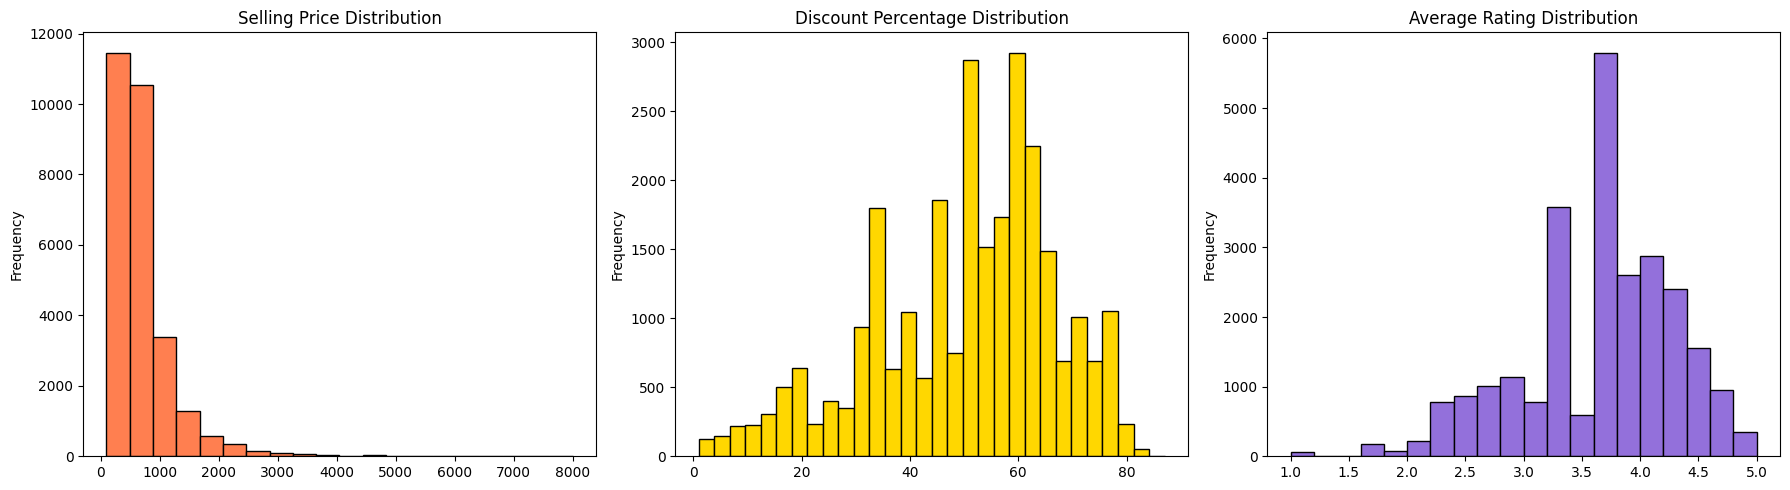

In [25]:
# Summary Statistics for Numerical Fields
numeric_cols = ['selling_price_num', 'actual_price_num', 'discount_num', 'average_rating_num']
display(df[numeric_cols].describe())

# Plotting Numerical Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df['selling_price_num'].plot(kind='hist', bins=20, ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Selling Price Distribution')

df['discount_num'].plot(kind='hist', bins=30, ax=axes[1], color='gold', edgecolor='black')
axes[1].set_title('Discount Percentage Distribution')

df['average_rating_num'].plot(kind='hist', bins=20, ax=axes[2], color='mediumpurple', edgecolor='black')
axes[2].set_title('Average Rating Distribution')

plt.tight_layout()
plt.show()

--- Out of Stock Distribution ---


out_of_stock
False    26436
True      1644
Name: count, dtype: int64

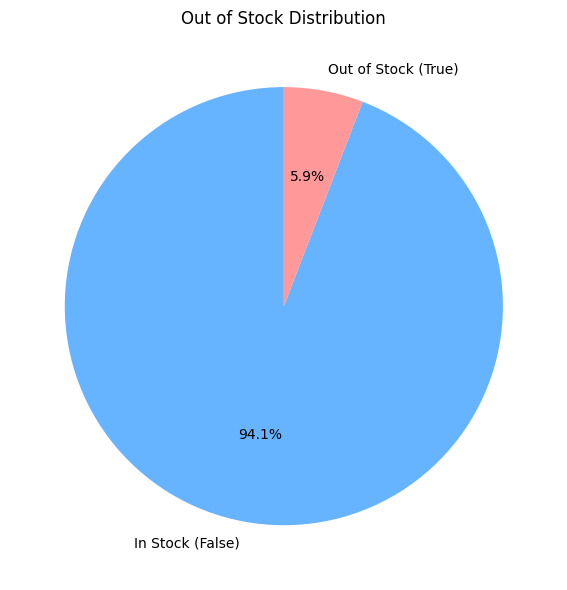

In [26]:
# Out of Stock Distribution (Pie Chart)
print("--- Out of Stock Distribution ---")
stock_counts = df['out_of_stock'].value_counts()
display(stock_counts)

plt.figure(figsize=(6, 6))
stock_counts.plot(
    kind='pie', 
    labels=['In Stock (False)', 'Out of Stock (True)'], 
    autopct='%1.1f%%', 
    colors=['#66b3ff', '#ff9999'], 
    startangle=90,
)
plt.title('Out of Stock Distribution')
plt.ylabel('') # Hides the default y-label
plt.tight_layout()
plt.show()

--- Top 10 Sellers by Product Count ---


seller
RetailNet                1411
SandSMarketing            887
BioworldMerchandising     842
ARBOR                     783
Keoti                     660
AFFGARMENTS               587
Black Beatle              548
AMALGUS ENTERPRISE        477
Tayab Manch Fashions      436
KAPSONSRETAILPVTLTD       415
Name: count, dtype: int64

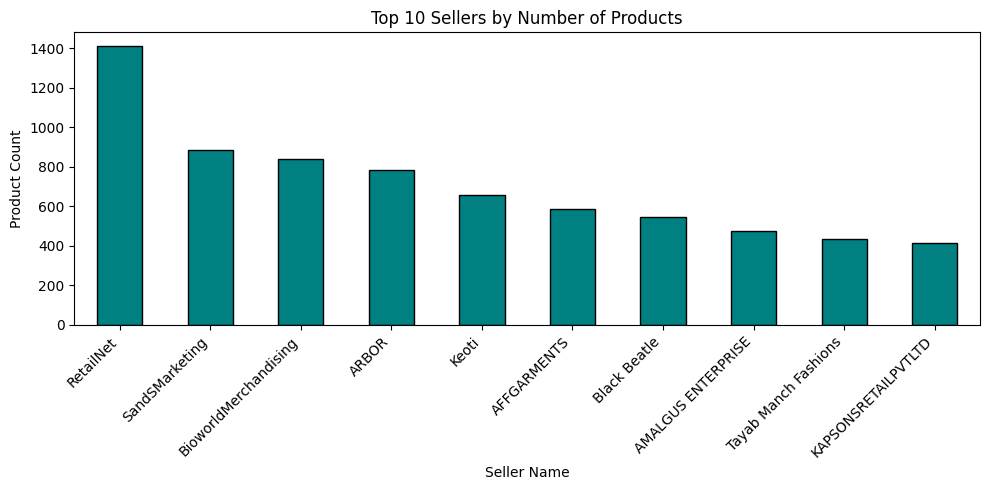


--- Top 10 Brands by Product Count ---


brand
ECKO Unl        951
Free Authori    860
ARBO            806
REEB            802
Pu              798
True Bl         793
Keo             660
Amp             585
Black Beat      548
vims rai        503
Name: count, dtype: int64

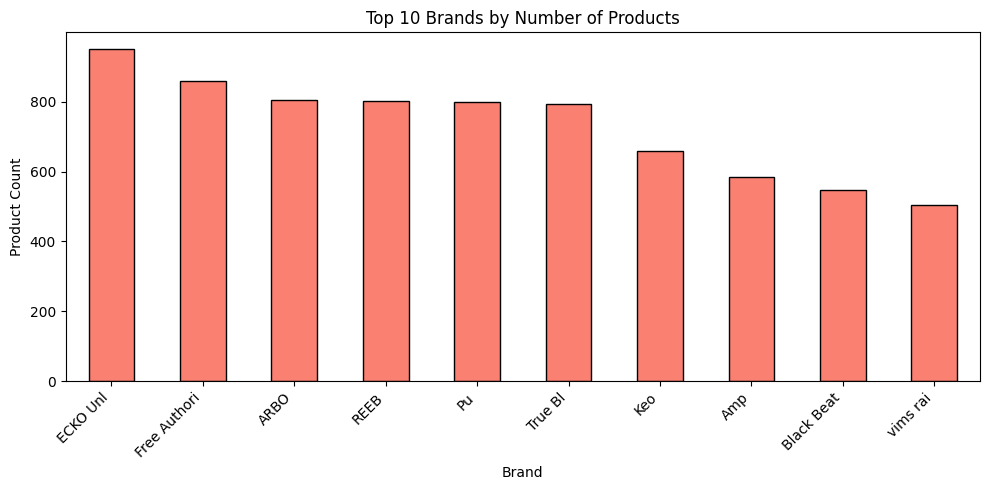


--- Top 10 Highest Rated Brands (Min 10 Products) ---


brand
VARTe          5.000000
SORA           4.609459
PixF           4.462195
Cots           4.444043
GYMBROTHE      4.407143
Zack Fo        4.330469
Fresh Fe       4.294737
U.S.Polo As    4.291304
Onei           4.233333
Gracew         4.231188
Name: average_rating_num, dtype: float64

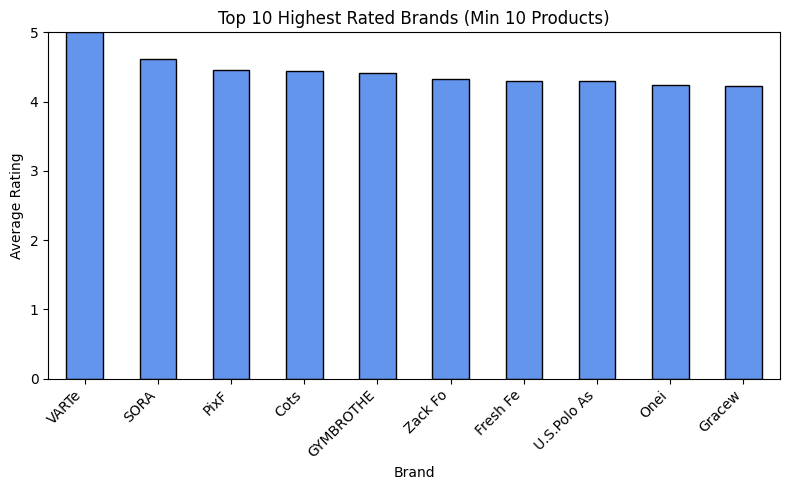

In [27]:
# Ranking by Sellers (Top 10 by Product Count)
print("--- Top 10 Sellers by Product Count ---")
seller_counts = df['seller'].value_counts().head(10)
display(seller_counts)

plt.figure(figsize=(10, 5))
seller_counts.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Top 10 Sellers by Number of Products')
plt.xlabel('Seller Name')
plt.ylabel('Product Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Ranking by Brands (Top 10 by Product Count)
print("\n--- Top 10 Brands by Product Count ---")
brand_counts = df['brand'].value_counts().head(10)
display(brand_counts)

plt.figure(figsize=(10, 5))
brand_counts.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Top 10 Brands by Number of Products')
plt.xlabel('Brand')
plt.ylabel('Product Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Ranking by Brands (Top 10 Highest Rated Brands with at least 10 products)
print("\n--- Top 10 Highest Rated Brands (Min 10 Products) ---")
# Filter out brands with very few products to avoid skewed 5.0 ratings
popular_brands = df.groupby('brand').filter(lambda x: len(x) >= 10)
top_rated_brands = popular_brands.groupby('brand')['average_rating_num'].mean().sort_values(ascending=False).head(10)
display(top_rated_brands)

plt.figure(figsize=(8, 5))
top_rated_brands.plot(kind='bar', color='cornflowerblue', edgecolor='black')
plt.title('Top 10 Highest Rated Brands (Min 10 Products)')
plt.xlabel('Brand')
plt.ylabel('Average Rating')
plt.ylim(0, 5) # Ratings are on a 0-5 scale
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [28]:
# Product Rankings

# Ranking by Rating (Top 5)
print("--- Top 5 Highest Rated Products ---")
display(df.sort_values(by='average_rating_num', ascending=False)[['title', 'average_rating_num', 'selling_price_num']].head(5))

# Ranking by Price (Top 5 Most Expensive)
print("\n--- Top 5 Most Expensive Products ---")
display(df.sort_values(by='selling_price_num', ascending=False)[['pid', 'title', 'selling_price', 'brand']].head(5))

# Ranking by Discount (Top 5 Heaviest Discounts)
print("\n--- Top 5 Heaviest Discounted Products ---")
display(df.sort_values(by='discount_num', ascending=False)[['pid', 'title', 'discount', 'actual_price', 'selling_price']].head(5))

--- Top 5 Highest Rated Products ---


,title,average_rating_num,selling_price_num
12339,Graphic Print Women Round Neck White T-Shirt,5.0,1499.0
12334,"Printed, Solid Men Round Neck Black T-Shirt",5.0,449.0
12348,"Solid Women Round Neck Black, Grey T-Shirt",5.0,449.0
27767,Solid Women Round Neck Blue T-Shirt,5.0,385.0
19971,Regular Fit Men Grey Satin Blend Trousers,5.0,1074.0



--- Top 5 Most Expensive Products ---


,pid,title,selling_price,brand
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,"7,999",REEB
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,"7,998",True Bl
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,"7,799",Pu
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,"7,799",Pu
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,"7,794",G



--- Top 5 Heaviest Discounted Products ---


,pid,title,discount,actual_price,selling_price
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,87% off,998,128
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,86% off,999,136
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,86% off,999,136
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,85% off,"2,999",449
520,TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",84% off,"1,299",201


# **Part 2:** Indexing and evaluation

In [29]:
from collections import defaultdict, Counter
import math
import os

In [30]:
SEARCHING_FIELDS = {
    "title": "title_processed",
    "description": "description_processed",
    "brand": "brand_processed",
    "category": "category_processed",
    "sub_category": "sub_category_processed",
    "product_details": "product_details_processed",
    "seller": "seller_processed"
}

FIELDS_WEIGHTS = {
    "title": 3.0,
    "description": 1.5,
    "brand": 2.0,
    "category": 1.0,
    "sub_category": 1.5,
    "product_details": 1.0,
    "seller": 0.5
}

# Keep only rows with a valid PID
index_df = df.dropna(subset=["pid"]).copy()
index_df["pid"] = index_df["pid"].astype(str)

if index_df["pid"].duplicated().any():
    raise ValueError("PID values must be unique before building the index.")

# Missing processed fields behave as empty token lists
for field, column in SEARCHING_FIELDS.items():
    value = index_df[column]
    if isinstance(value, list):
        index_df[column] = value
    else: []

N_DOCUMENTS = len(index_df)
print("Documents to index:", N_DOCUMENTS)
print("Searchable fields:", list(SEARCHING_FIELDS))

Documents to index: 28080
Searchable fields: ['title', 'description', 'brand', 'category', 'sub_category', 'product_details', 'seller']


In [31]:
inverted_index = {
    field: defaultdict(dict) for field in SEARCHING_FIELDS
}

# Build the inverted index
for _, row in index_df.iterrows():
    pid = row["pid"]

    for field, column in SEARCHING_FIELDS.items():
        tokens = row[column]
        if not isinstance(tokens, list):
            continue
        term_counts = Counter(tokens)

        for term, frequency in term_counts.items():
            inverted_index[field][term][pid] = frequency

# Convert defaultdicts to regular dicts for clear display
inverted_index = {
    field: dict(term_postings) for field, term_postings in inverted_index.items()
}

# Compute the document frequency for each term and the total vocabulary across all fields
document_frequency = defaultdict(int)

all_terms = set()

for field in SEARCHING_FIELDS:
    all_terms.update(inverted_index[field].keys())

for term in all_terms:
    matching_pid = set()
    for field in SEARCHING_FIELDS:
        matching_pid.update(inverted_index[field].get(term, {}).keys())
    document_frequency[term] = len(matching_pid)

vocabulary = set(all_terms)

print("Number of indexed documents:", N_DOCUMENTS)
print("Vocabulary size across searchable fields:", len(vocabulary))
print("Number of terms in each field:")
for field in SEARCHING_FIELDS:
    print(f"  {field}: {len(inverted_index[field])}")

Number of indexed documents: 28080
Vocabulary size across searchable fields: 20031
Number of terms in each field:
  title: 729
  description: 4699
  brand: 402
  category: 7
  sub_category: 39
  product_details: 16770
  seller: 683


In [32]:
def get_postings(term):
    """Returns {pid: {field: term_frequency}} for a term across all fields"""
    result = defaultdict(dict)

    for field in SEARCHING_FIELDS:
        postings = inverted_index[field].get(term, {})
        for pid, frequency in postings.items():
            result[pid][field] = frequency

    return dict(result)

def conjunctive_search(query):
    """Return PIDs containing every preprocessed query term"""
    query_terms = list(dict.fromkeys(preprocess_text(query)))  # Remove duplicates while preserving order

    if not query_terms:
        return []

    term_postings = [get_postings(term) for term in query_terms]

    # If any term has no postings, return an empty list immediately
    if any(not postings for postings in term_postings):
        return []

    # Find the intersection of PIDs across all query terms
    matching_pids = set(term_postings[0].keys())
    for postings in term_postings[1:]:
        matching_pids.intersection_update(postings.keys())

    return list(matching_pids)

# Check the two predefined validation queries from Part 1
validation_queries = [
    "women full sleeve sweatshirt cotton",
    "men slim jeans blue",
]

for query in validation_queries:
    matching_pids = conjunctive_search(query)
    print(f"Query: '{query}'")
    print(f"Matching PIDs: {matching_pids}")
    print(f"Number of matching products: {len(matching_pids)}\n")

Query: 'women full sleeve sweatshirt cotton'
Matching PIDs: ['TSHFYNDSQNARK8NB', 'SWSFX5WWZRMVHG82', 'SWSFPGX2M7SXUMP7', 'SWSFY4ZTY3GJYWZP', 'SWSFYGGANZCHYFEY', 'JCKFM7EFHW5QQGHF', 'SWSFXZWGCNDAPG5H', 'SWSFXMKRPXYAHCMQ', 'SWSFXNFS7CY3GSXE', 'SWSFUNF6XHCGGVCU', 'SWSFWEFYPBFDQFR7', 'TKTFJY5UCHHFYG6C', 'SWSFM4YXPFYQGFGY', 'SWSFMJGTVFW3NAXZ', 'SWSFWCSPDEGMNXZC', 'SWSF9W4TTB2M9ZXT', 'SWSFWEYZN5CY2DWE', 'SWSFWG9BHYUMNSPG', 'SWSFY37MCKGY6GHQ', 'SWSFWFW7JZBEZART', 'SWSFVZRFVZ2SZ3HZ', 'SWSFRR7P3P6CQQK6', 'SWSFJV9XVQ2RRJQE', 'JCKFNEWRZPADUNHM', 'JCKFMEG8S2SMYYF6', 'SWSFP4V9B6MGRMFB', 'SWSFZ2H4KMYXZXX7', 'SWSFXW9SZBVXAUUV', 'SWSFRAKJY6ZYPFFU', 'SWSFTEMF3HZZPGH2', 'SWSFXNFSHQGA4PXH', 'TSHFV2GGAZVCY8D3', 'TSHFVGBV8CPDDAWK', 'SWSEYQQW6KZSAGZB', 'SWSFM2W3BDGF9EXM', 'JCKFTZBC3DMCVYXH', 'SWSFFVKBCQG5FHPF', 'SWSF892278SFMX6E', 'TSHFZDP7PHDKFFDC', 'SWSFXZWGMGVDUCXA', 'SWSFMJZHZFUCHHTH', 'SWSFWEYZC9EEYB6E', 'SWSFN8YZW4VPXW7W', 'SWSFWCS9DZGKEGVG', 'SWSFWAV3BFPR8ED9', 'SWSFZ2H4HAGJHZW4', 'SWSEDQEAR4ZGTJ9K',

In [33]:
test_queries = [
    "women hoodie polycotton red graphic print",
    "men wide blue v-neck t-shirt",
    "summer dress pink",
    "yellow running shoes",
    "raincoat waterproof women",
]

for query in test_queries:
    matching_pids = conjunctive_search(query)
    print(f"Query: '{query}'")
    print(f"Matching PIDs: {matching_pids}")
    print(f"Number of matching products: {len(matching_pids)}\n")

Query: 'women hoodie polycotton red graphic print'
Matching PIDs: ['SWSFWCXHFRX2DBSG', 'SWSFWCSNPENAZRZM', 'SWSFWCTDHRABJFCR', 'SWSFWCSZGNU7N4F6', 'SWSFWCSNXA6U57G5', 'SWSFWCSNPEDVPS7Z', 'SWSFWCXMJRZDWKVU', 'SWSFWCSPEGMDH8FV', 'SWSFWEYZVYXHPGQJ', 'SWSFWEYZC9EEYB6E', 'SWSFWCSPHDFH5YKT', 'SWSFWEF36Z3RKTJ7', 'SWSFWEYZZZEJEEJW']
Number of matching products: 13

Query: 'men wide blue v-neck t-shirt'
Matching PIDs: ['TSHE7GY3D5WWFKZR', 'TSHEXZ8KJC9GHZCH', 'TSHENWW53TW4EGWG', 'TSHF4ZFXV3VHZ5GU', 'TSHFNUGTDBPCWZ3Q', 'TSHFACN2M6QJZG6Z', 'TSHE8UHZ6WFVCCNU', 'TSHFACNYDBQQYHPZ', 'TSHFNUHHSKB9Y9HM', 'TSHFGH2XTNZFHENV', 'TSHEXZ8KTZVQJECU']
Number of matching products: 11

Query: 'summer dress pink'
Matching PIDs: ['TSHFHBNTG8D4E3XN', 'TSHFHHRKEPUSJMC8', 'TSHFHBNT5DVSQSVY', 'TSHFHHRHH8THU3VZ', 'TSHFHHRK9J4E65VB', 'TSHFHBNTNGCX5ZZ5', 'TSHFHBNTZUF4YSQZ', 'TSHFHBNTBDDNHHYJ', 'TSHFHHRKZ5CYHUXZ', 'TSHFHBNTU4YCFH4E', 'TSHFHHRKQHBDDUWQ', 'TSHFHBNUYR87ZX8A', 'TSHFHBNTFMXFGZYG', 'TSHFHBNTHZB6Z6DN', 'TSHFHBNTJ

In [34]:
def compute_tfidf_score(pid, query_terms):
    """Calculate a field-weighted TF-IDF score for one document"""
    score = 0.0

    for term in query_terms:
        df_term = document_frequency.get(term, 0)
        if df_term == 0:
            continue  # Skip terms not in the vocabulary

        idf = math.log((N_DOCUMENTS + 1)/(df_term + 1)) + 1  # Smoothed IDF

        for field in SEARCHING_FIELDS:
            tf = inverted_index[field].get(term, {}).get(pid, 0)
            if tf > 0:
                tf_weighted = 1 + math.log(tf)  # Logarithmic TF
                score += tf_weighted * idf * FIELDS_WEIGHTS[field]

    return score

def search_rank(query, topk = 10):
    """Return top-k PIDs ranked by field-weighted TF-IDF score"""
    query_terms = list(dict.fromkeys(preprocess_text(query)))  # Remove duplicates while preserving order

    if not query_terms:
        return []

    candidate_pids = conjunctive_search(query)

    if not candidate_pids:
        return []

    ranked = [(pid, compute_tfidf_score(pid, query_terms)) for pid in candidate_pids]

    ranked.sort(key=lambda item: (-item[1], item[0]))

    return ranked[:topk]

def display_search_results(query, topk=10):
    """Display the ranked top-k search results for a query"""
    ranked_results = search_rank(query, topk)

    if not ranked_results:
        print(f"No results found for query: '{query}'")
        return

    result_pids = [pid for pid, score in ranked_results]

    original_docs = (df.drop_duplicates(subset=["pid"]).set_index("pid", drop=False))

    results = original_docs.loc[result_pids].copy()
    results["score"] = [score for pid, score in ranked_results]

    display_columns = [
        "pid", "title", "description", "brand", "category",
        "sub_category", "product_details", "seller", "out_of_stock",
        "selling_price", "discount", "actual_price",
        "average_rating", "url", "tfidf_score"
    ]
    
    display(results[[col for col in display_columns if col in results.columns]])
    return results

In [35]:
for query in test_queries:
    print("\n" + "=" * 90)
    print("QUERY:", query)
    display_search_results(query, topk=10)



QUERY: women hoodie polycotton red graphic print


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
pid,,,,,,,,,,,,,,
SWSFWEF36Z3RKTJ7,SWSFWEF36Z3RKTJ7,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Printed Sweatshir...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,849,50% off,"1,699",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWCSNXA6U57G5,SWSFWCSNXA6U57G5,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,799,50% off,"1,599",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWCSPEGMDH8FV,SWSFWCSPEGMDH8FV,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,849,50% off,"1,699",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWCSPHDFH5YKT,SWSFWCSPHDFH5YKT,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,949,50% off,"1,899",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWCXHFRX2DBSG,SWSFWCXHFRX2DBSG,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,799,50% off,"1,599",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWCXMJRZDWKVU,SWSFWCXMJRZDWKVU,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,824,45% off,"1,499",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWEYZC9EEYB6E,SWSFWEYZC9EEYB6E,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,824,45% off,"1,499",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWEYZVYXHPGQJ,SWSFWEYZVYXHPGQJ,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,849,50% off,"1,699",3.9,https://www.flipkart.com/free-authority-full-s...
SWSFWEYZZZEJEEJW,SWSFWEYZZZEJEEJW,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Free Authori,Clothing and Accessories,Winter Wear,"[{'Color': 'Red'}, {'Fabric': 'Polycotton'}, {...",BioworldMerchandising,False,849,50% off,"1,699",3.9,https://www.flipkart.com/free-authority-full-s...



QUERY: men wide blue v-neck t-shirt


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
pid,,,,,,,,,,,,,,
TSHEXZ8KTZVQJECU,TSHEXZ8KTZVQJECU,"Solid Men V-neck Silver, Blue T-Shirt","Cotton Blend Fabric,V-neck Blue-Milanch T-shir...",HUMBE,Clothing and Accessories,Topwear,"[{'Type': 'V-neck'}, {'Sleeve': 'Half Sleeve'}...",HUMBERT,False,299,40% off,499,2,https://www.flipkart.com/humbert-solid-men-v-n...
TSHFNUHHSKB9Y9HM,TSHFNUHHSKB9Y9HM,Solid Men V Neck Blue T-Shirt,Arbour gives you the new trends t-shirt for me...,ARBO,Clothing and Accessories,Topwear,"[{'Type': 'V Neck'}, {'Sleeve': 'Full Sleeve'}...",ARBOR,False,360,39% off,599,3.9,https://www.flipkart.com/arbour-solid-men-v-ne...
TSHFNUGTDBPCWZ3Q,TSHFNUGTDBPCWZ3Q,Solid Men V Neck Light Blue T-Shirt,Arbour gives you the new trends t-shirt for me...,ARBO,Clothing and Accessories,Topwear,"[{'Type': 'V Neck'}, {'Sleeve': 'Full Sleeve'}...",ARBOR,False,360,39% off,599,3.9,https://www.flipkart.com/arbour-solid-men-v-ne...
TSHFACN2M6QJZG6Z,TSHFACN2M6QJZG6Z,Solid Men V-Neck Blue T-Shirt,NaN,Dudli,Clothing and Accessories,Topwear,"[{'Type': 'V-Neck'}, {'Sleeve': 'Half Sleeve'}...",DudlindFashion,False,299,70% off,999,4.6,https://www.flipkart.com/dudlind-solid-men-v-n...
TSHENWW53TW4EGWG,TSHENWW53TW4EGWG,Solid Men V-neck Multicolor T-Shirt (Pack of 3),"Cotton Blend Fabric,V-neck Charcoal, Royal Blu...",HUMBE,Clothing and Accessories,Topwear,"[{'Type': 'V-neck'}, {'Sleeve': 'Half Sleeve'}...",HUMBERT,False,599,33% off,899,4.3,https://www.flipkart.com/humbert-solid-men-v-n...
TSHEXZ8KJC9GHZCH,TSHEXZ8KJC9GHZCH,Solid Men V-neck Multicolor T-Shirt (Pack of 3),"Cotton Blend Fabric,V-neck Blue Milanch, Mint ...",HUMBE,Clothing and Accessories,Topwear,"[{'Type': 'V-neck'}, {'Sleeve': 'Half Sleeve'}...",HUMBERT,False,457,42% off,799,3.9,https://www.flipkart.com/humbert-solid-men-v-n...
TSHFACNYDBQQYHPZ,TSHFACNYDBQQYHPZ,Striped Men V-neck Blue T-Shirt,NaN,Dudli,Clothing and Accessories,Topwear,"[{'Type': 'V-neck'}, {'Sleeve': 'Half Sleeve'}...",DudlindFashion,False,299,70% off,999,3.8,https://www.flipkart.com/dudlind-striped-men-v...
TSHFGH2XTNZFHENV,TSHFGH2XTNZFHENV,"Printed, Solid Men V Neck Red, Blue, Grey T-Sh...",You wiil love the softness and durabbility of ...,Amp,Clothing and Accessories,Topwear,"[{'Type': 'V Neck'}, {'Sleeve': 'Short Sleeve'...",AFFGARMENTS,False,525,64% off,"1,499",3.4,https://www.flipkart.com/ample-printed-solid-m...
TSHE7GY3D5WWFKZR,TSHE7GY3D5WWFKZR,Printed Men V-neck Light Blue T-Shirt,NaN,T10 Spor,Clothing and Accessories,Topwear,"[{'Type': 'V-neck'}, {'Sleeve': 'Half Sleeve'}...",T10Sports,False,478,52% off,999,4,https://www.flipkart.com/t10-sports-printed-me...



QUERY: summer dress pink


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
pid,,,,,,,,,,,,,,
TSHFHBNT248XX2GX,TSHFHBNT248XX2GX,"Solid Women Polo Neck Pink, Black, Light Green...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.9,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNT4HAKCDBF,TSHFHBNT4HAKCDBF,"Solid Women Polo Neck Pink, Light Green, Yello...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.9,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNT5DVSQSVY,TSHFHBNT5DVSQSVY,"Solid Men Polo Neck Light Blue, Green, Pink T-...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.8,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNT7PMKUZWT,TSHFHBNT7PMKUZWT,"Solid Women Polo Neck Light Blue, Pink, Light ...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.9,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNT82GDFEV8,TSHFHBNT82GDFEV8,"Solid Men Polo Neck Green, Blue, Pink T-Shirt ...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.8,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNT8TVE7ZHZ,TSHFHBNT8TVE7ZHZ,"Solid Women Polo Neck Light Blue, Blue, Pink T...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.8,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNT9KUPGYQY,TSHFHBNT9KUPGYQY,"Solid Men Polo Neck Green, Pink, Black T-Shirt...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.8,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNTAZD28YCW,TSHFHBNTAZD28YCW,"Solid Women Polo Neck Dark Blue, Green, Pink T...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.8,https://www.flipkart.com/keoti-solid-men-polo-...
TSHFHBNTBDDNHHYJ,TSHFHBNTBDDNHHYJ,"Solid Men Polo Neck Green, Pink, Light Green T...",EXPERIENCE THE AMAZING COMFORT OF A KEOTI POLO...,Keo,Clothing and Accessories,Topwear,"[{'Type': 'Polo Neck'}, {'Sleeve': 'Half Sleev...",Keoti,False,664,63% off,"1,799",3.8,https://www.flipkart.com/keoti-solid-men-polo-...



QUERY: yellow running shoes


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
pid,,,,,,,,,,,,,,
SHOEC87DCYYZH7MF,SHOEC87DCYYZH7MF,"RS-5006 Running Shoes For Women (Black, Yellow)",Vector X Is One Of The Established Sports Bran...,Vector,Footwear,Men's Footwear,"[{'Color': 'Black, Yellow'}, {'Outer Material'...",SOCCERINTERNATIONAL,False,"1,170",9% off,"1,299",4,https://www.flipkart.com/vector-x-rs-5006-runn...
SHOFTZFQQYKC8HY6,SHOFTZFQQYKC8HY6,Running Shoes For Men (Yellow),NaN,Bone,Footwear,Men's Footwear,"[{'Color': 'Yellow'}, {'Outer Material': 'Synt...",Manojsunda,False,341,65% off,999,4.1,https://www.flipkart.com/bonexy-running-shoes-...



QUERY: raincoat waterproof women


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
pid,,,,,,,,,,,,,,
RNCFG4PHHGHSA3YH,RNCFG4PHHGHSA3YH,Solid Men Raincoat,Type: rain suit a coat ; a pant waterproof mat...,Wet Off Ho,Clothing and Accessories,Raincoats,"[{'Sales Package': '1 raincoat'}, {'Fabric Car...",X Studio,False,799,55% off,"1,788",3.8,https://www.flipkart.com/wet-off-hood-solid-me...
RNCFWZVGXMGUQDXW,RNCFWZVGXMGUQDXW,Solid Men Raincoat,Type: rain suit a coat ; a pant waterproof mat...,Wet Off Ho,Clothing and Accessories,Raincoats,[{'Sales Package': '1 Piece rain coats for men...,X Studio,False,766,74% off,"2,999",4.4,https://www.flipkart.com/wet-off-hood-solid-me...
RNCFGGTR5JWV8ES9,RNCFGGTR5JWV8ES9,Solid Men Raincoat,Type: rain suit a coat ; a pant waterproof mat...,Wet Off Ho,Clothing and Accessories,Raincoats,"[{'Sales Package': '1 raincoat'}, {'Fabric Car...",X Studio,False,799,55% off,"1,788",3.8,https://www.flipkart.com/wet-off-hood-solid-me...
RNCFQH2E5FGYYXXF,RNCFQH2E5FGYYXXF,Solid Women Raincoat,Raincoats for women Made from fabric Hipura Ny...,The Dry Ca,Clothing and Accessories,Raincoats,"[{'Fabric Care': 'Cold Water Wash Only'}, {'Sl...",Newera,False,"1,095",69% off,"3,588",3.9,https://www.flipkart.com/dry-cape-solid-men-ra...
RNCFQH2EAAE4SDYE,RNCFQH2EAAE4SDYE,Solid Women Raincoat,Raincoats for women Made from fabric Hipura Ny...,The Dry Ca,Clothing and Accessories,Raincoats,"[{'Fabric Care': 'Cold Water Wash Only'}, {'Sl...",Newera,False,"1,095",69% off,"3,588",3.9,https://www.flipkart.com/dry-cape-solid-men-ra...
RNCFY9RXFPXY3HYT,RNCFY9RXFPXY3HYT,Solid Women Raincoat,Shop from a wide range of Bicolor Raincoats fr...,Wet Off Ho,Clothing and Accessories,Raincoats,"[{'Sales Package': '1 raincoat'}, {'Fabric Car...",X Studio,False,995,74% off,"3,888",4.7,https://www.flipkart.com/wet-off-hood-solid-me...
RNCFYMZ6AKKHRJC4,RNCFYMZ6AKKHRJC4,Solid Men Raincoat,Shop from a wide range of Bicolor Raincoats fr...,The Dry Ca,Clothing and Accessories,Raincoats,"[{'Sales Package': '1 piece raincoat'}, {'Fabr...",Newera,False,999,52% off,"2,088",4.7,https://www.flipkart.com/dry-cape-solid-men-ra...
RNCFXRFSHREUUZCN,RNCFXRFSHREUUZCN,Solid Men Raincoat,NaN,Wet Off Ho,Clothing and Accessories,Raincoats,"[{'Sales Package': '1 Pcs Raincoat'}, {'Fabric...",X Studio,False,995,74% off,"3,888",4,https://www.flipkart.com/wet-off-hood-solid-me...
RNCE7A3XWSDRGNWX,RNCE7A3XWSDRGNWX,Galaxy Reverseable Impenetrable Moisture Barri...,Impenetrable Moisture Barrier To Guarantee Dry...,The Dry Ca,Clothing and Accessories,Raincoats,"[{'Sales Package': '1 Rainsuit'}, {'Fabric Car...",Newera,False,845,52% off,"1,788",3.4,https://www.flipkart.com/dry-cape-galaxy-rever...


In [36]:
def precision_at_k(ranked_pids, relevant_pids, k):
    """Calculate precision at k for a ranked list of PIDs"""
    if k <= 0:
        return -1  # Invalid k value

    top_k_pids = ranked_pids[:k]
    if not relevant_pids:
        return 0.0

    relevant_count = sum(pid in relevant_pids for pid in top_k_pids)
    return relevant_count / k

def recall_at_k(ranked_pids, relevant_pids, k):
    """Calculate recall at k for a ranked list of PIDs"""
    if k <= 0:
        return -1  # Invalid k value

    top_k_pids = ranked_pids[:k]
    if not relevant_pids:
        return 0.0  # No relevant documents to recall

    relevant_count = sum(pid in relevant_pids for pid in top_k_pids)
    return relevant_count / len(relevant_pids)

def average_precision_at_k(ranked_pids, relevant_pids, k):
    """Calculate average precision at k for a ranked list of PIDs"""
    if k <= 0:
        return -1  # Invalid k value

    top_k_pids = ranked_pids[:k]
    if not relevant_pids:
        return 0.0  # No relevant documents to evaluate

    hits = 0
    precision_sum = 0.0

    for rank, pid in enumerate(top_k_pids, start=1):
        if pid in relevant_pids:
            hits += 1
            precision_sum += hits/rank

    denominator = min(len(relevant_pids), k)
    return precision_sum / denominator if denominator > 0 else 0.0

def F1_score_at_k(ranked_pids, relevant_pids, k):
    """Calculate F1 score at k for a ranked list of PIDs"""
    p = precision_at_k(ranked_pids, relevant_pids, k)
    r = recall_at_k(ranked_pids, relevant_pids, k)

    if p + r == 0:
        return 0.0  # Avoid division by zero

    return (2 * p * r)/(p + r)

def mean_average_precision_at_k(ranked_lists, relevance_by_query, k):
    """Calculate mean average precision at k (MAP) for multiple queries"""
    values = [average_precision_at_k(ranked_lists[q], relevance_by_query[q], k) for q in ranked_lists]

    if not values:
        return 0.0  # Avoid division by zero if there are no queries
    
    return float(np.mean(values))

def reciprocal_rank(ranked_pids, relevant_pids):
    """Calculate reciprocal rank for a ranked list of PIDs"""
    for rank, pid in enumerate(ranked_pids, start=1):
        if pid in relevant_pids:
            return 1.0/rank
        
    return 0.0  # No relevant documents found

def mean_reciprocal_rank(ranked_lists, relevance_by_query):
    """Calculate mean reciprocal rank (MRR) for multiple queries"""
    values = [reciprocal_rank(ranked_lists[q], relevance_by_query[q]) for q in ranked_lists]

    return float(np.mean(values)) if values else 0.0

def ndcg_at_k(ranked_pids, relevant_pids, k):
    """Calculate normalized discounted cumulative gain (NDCG) at k for a ranked list of PIDs"""
    if k <= 0:
        return -1  # Invalid k value

    gains = [1 if pid in relevant_pids else 0 for pid in ranked_pids[:k]]

    dcg = sum(gain / math.log2(rank + 1) for rank, gain in enumerate(gains, start=1))

    ideal_relevant = min(len(relevant_pids), k)
    if ideal_relevant == 0:
        return 0.0

    ideal_dcg = sum(1 / math.log2(rank + 1)for rank in range(1, ideal_relevant + 1))
    if ideal_dcg == 0:
        return 0.0

    return dcg / ideal_dcg

### Validation evaluation (K=10)

In [ ]:
validation_labels = pd.read_csv("../../data/validation_labels.csv")

validation_queries = {
    1: "women full sleeve sweatshirt cotton",
    2: "men slim jeans blue",
}
evaluation_k = 10

if validation_labels[["pid", "query_id", "labels"]].isna().any().any():
    raise ValueError("Validation labels contain missing required values.")
if set(validation_labels["query_id"].unique()) != set(validation_queries):
    raise ValueError("Validation labels do not contain exactly the predefined queries.")
if not validation_labels["labels"].isin([0, 1]).all():
    raise ValueError("Validation labels must be binary (0 or 1).")
if validation_labels.duplicated(["query_id", "pid"]).any():
    raise ValueError("Validation labels contain duplicate query/PID pairs.")

ranked_pids_by_query = {}
relevant_pids_by_query = {}
for query_id, query in validation_queries.items():
    judgments = validation_labels[validation_labels["query_id"] == query_id]
    ranked_pids_by_query[query_id] = [
        pid for pid, _ in search_rank(query, topk=evaluation_k)
    ]
    relevant_pids_by_query[query_id] = set(
        judgments.loc[judgments["labels"] == 1, "pid"].astype(str)
    )

metric_results = {}
for query_id, ranked_pids in ranked_pids_by_query.items():
    relevant_pids = relevant_pids_by_query[query_id]
    metric_results[f"Query {query_id}"] = {
        "P@10": precision_at_k(ranked_pids, relevant_pids, evaluation_k),
        "R@10": recall_at_k(ranked_pids, relevant_pids, evaluation_k),
        "AP@10": average_precision_at_k(ranked_pids, relevant_pids, evaluation_k),
        "F1@10": F1_score_at_k(ranked_pids, relevant_pids, evaluation_k),
        "NDCG@10": ndcg_at_k(ranked_pids, relevant_pids, evaluation_k),
    }

validation_metrics = pd.DataFrame.from_dict(metric_results, orient="index")
display(validation_metrics.apply(lambda column: column.map(lambda value: f"{value:.3f}")))

aggregate_metrics = pd.DataFrame(
    {
        "MAP@10": [mean_average_precision_at_k(ranked_pids_by_query, relevant_pids_by_query, evaluation_k)],
        "MRR@10": [mean_reciprocal_rank(ranked_pids_by_query, relevant_pids_by_query)],
    },
    index=["Overall"],
)
display(aggregate_metrics.apply(lambda column: column.map(lambda value: f"{value:.3f}")))

,P@10,R@10,AP@10,F1@10,NDCG@10
Query 1,0.100,0.077,0.025,0.087,0.095
Query 2,0.000,0.000,0.000,0.000,0.000


,MAP@10,MRR@10
Overall,0.013,0.125


In [ ]:
# Create a complete PID-by-query judgment template.
manual_judgments_path = "manual_test_relevance.csv"

manual_judgments = pd.MultiIndex.from_product(
    [test_queries, index_df["pid"].astype(str).unique()], names=["query", "pid"]).to_frame(index=False)

# Add a relevance column initialized to 0 (not relevant)
manual_judgments["relevance"] = 0

# Save the template to a CSV file if it doesn't already exist
if not os.path.exists(manual_judgments_path):
    manual_judgments.to_csv(manual_judgments_path, index=False)
    print(f"Created {manual_judgments_path}. "
        "Review products and change relevance from 0 to 1 where appropriate."
    )
else:
    print(f"{manual_judgments_path} already exists; it was not overwritten.")

display(manual_judgments.head())


Created manual_test_relevance.csv. Review products and change relevance from 0 to 1 where appropriate.


,query,pid,relevance
0,women hoodie polycotton red graphic print,TKPFCZ9EA7H5FYZH,0
1,women hoodie polycotton red graphic print,TKPFCZ9EJZV2UVRZ,0
2,women hoodie polycotton red graphic print,TKPFCZ9EHFCY5Z4Y,0
3,women hoodie polycotton red graphic print,TKPFCZ9ESZZ7YWEF,0
4,women hoodie polycotton red graphic print,TKPFCZ9EVXKBSUD7,0


In [ ]:
# Create a ground-truth review file using the top 25 results per query

evaluation_k = 25
evaluation_candidates = []

for query in test_queries:

    # Retrieve the top 25 ranked products
    ranked_results = search_rank(query, topk=evaluation_k)

    for pid, score in ranked_results:
        evaluation_candidates.append({"query": query, "pid": str(pid), "relevance": 0})

# Convert results into a DataFrame
manual_judgments = pd.DataFrame(evaluation_candidates)

# Add product information for manual relevance assessment
original_documents = df.drop_duplicates(subset="pid").copy()

original_documents["pid"] = original_documents["pid"].astype(str)

product_information = original_documents[
    ["pid", "title", "description", "category",
     "sub_category", "brand"]].copy()

manual_judgments = manual_judgments.merge(product_information, on="pid", how="left")

# Save the ground-truth file
manual_judgments.to_csv("manual_test_relevance.csv", index=False)

print("Ground-truth file created!")
print("Number of products to evaluate:", len(manual_judgments))

Ground-truth file created!
Number of products to evaluate: 61


,query,pid,relevance,title,description,category,sub_category,brand
0,women hoodie polycotton red graphic print,SWSFWEF36Z3RKTJ7,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Printed Sweatshir...,Clothing and Accessories,Winter Wear,Free Authori
1,women hoodie polycotton red graphic print,SWSFWCSNXA6U57G5,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Clothing and Accessories,Winter Wear,Free Authori
2,women hoodie polycotton red graphic print,SWSFWCSPEGMDH8FV,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Clothing and Accessories,Winter Wear,Free Authori
3,women hoodie polycotton red graphic print,SWSFWCSPHDFH5YKT,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Clothing and Accessories,Winter Wear,Free Authori
4,women hoodie polycotton red graphic print,SWSFWCXHFRX2DBSG,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Clothing and Accessories,Winter Wear,Free Authori
5,women hoodie polycotton red graphic print,SWSFWCXMJRZDWKVU,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Sweatsh...,Clothing and Accessories,Winter Wear,Free Authori
6,women hoodie polycotton red graphic print,SWSFWEYZC9EEYB6E,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Clothing and Accessories,Winter Wear,Free Authori
7,women hoodie polycotton red graphic print,SWSFWEYZVYXHPGQJ,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Clothing and Accessories,Winter Wear,Free Authori
8,women hoodie polycotton red graphic print,SWSFWEYZZZEJEEJW,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Clothing and Accessories,Winter Wear,Free Authori
9,women hoodie polycotton red graphic print,SWSFWCSNPEDVPS7Z,0,Full Sleeve Graphic Print Women Sweatshirt,Free Authority Presents this Crew Neck Terry S...,Clothing and Accessories,Winter Wear,Free Authori


In [ ]:
# Load the manually assigned relevance judgments

manual_df = pd.read_csv(manual_judgments_path)

manual_df["pid"] = manual_df["pid"].astype(str)
manual_df["relevance"] = pd.to_numeric(manual_df["relevance"], errors="coerce")

if manual_df[["query", "pid", "relevance"]].isna().any().any():
    raise ValueError("Manual relevance labels contain missing values.")
if not manual_df["relevance"].isin([0, 1]).all():
    raise ValueError("Relevance labels must be binary (0 or 1).")
if manual_df.duplicated(["query", "pid"]).any():
    raise ValueError("Duplicate query/PID pairs found.")

# Store relevant PIDs for each query
relevant_pids_by_query = {}

for query in test_queries:
    judgments = manual_df[manual_df["query"] == query]

    relevant_pids_by_query[query] = set(judgments.loc[judgments["relevance"] == 1, "pid"])

# Retrieve and rank documents for each query
evaluation_k = 10
ranked_pids_by_query = {}

for query in test_queries:

    ranked_results = search_rank(query, topk=evaluation_k)

    ranked_pids_by_query[query] = [str(pid) for pid, score in ranked_results]

# Calculate evaluation metrics
metric_results = {}

for query in test_queries:

    ranked_pids = ranked_pids_by_query[query]
    relevant_pids = relevant_pids_by_query[query]

    metric_results[query] = {
        "P@10": precision_at_k(ranked_pids, relevant_pids, evaluation_k),
        "R@10": recall_at_k(ranked_pids, relevant_pids, evaluation_k),
        "AP@10": average_precision_at_k(ranked_pids, relevant_pids, evaluation_k),
        "F1@10": F1_score_at_k(ranked_pids, relevant_pids, evaluation_k),
        "NDCG@10": ndcg_at_k(ranked_pids, relevant_pids, evaluation_k),
    }

test_metrics = pd.DataFrame.from_dict(metric_results, orient="index")
display(test_metrics.apply(lambda column: column.map(lambda value: f"{value:.3f}")))

# Calculate aggregate metrics
aggregate_metrics = pd.DataFrame(
    {
        "MAP@10": [mean_average_precision_at_k(ranked_pids_by_query, relevant_pids_by_query, evaluation_k)],
        "MRR": [mean_reciprocal_rank(ranked_pids_by_query, relevant_pids_by_query)],
    },
    index=["Overall"],
)

display(aggregate_metrics.apply(lambda column: column.map(lambda value: f"{value:.3f}")))


,P@10,R@10,AP@10,F1@10,NDCG@10
women hoodie polycotton red graphic print,0.000,0.000,0.000,0.000,0.000
men wide blue v-neck t-shirt,0.000,0.000,0.000,0.000,0.000
summer dress pink,0.000,0.000,0.000,0.000,0.000
yellow running shoes,0.000,0.000,0.000,0.000,0.000
raincoat waterproof women,0.000,0.000,0.000,0.000,0.000


,MAP@10,MRR
Overall,0.000,0.000
